# Stage 2, Version 3: Which Parts of the Loop Actually Matter?

Group PG-S2-36, Automatic Discovery of Interpretable Financial Factors
Abu Wakkas Bastob, 5 November 2026

At the prototype demo on 22 October, Dr Liu suggested three things for the next stage:

1. Compare our approaches with each other, since we now all use the same setting.
2. Do an ablation study: take the design apart and check how much each piece matters. His example was the choice of language model.
3. Try more iterations.

This notebook is my answer to all three. The idea of an ablation is simple. My loop has several parts (Claude, the report cards, the team trial, the pair trials, 8 rounds). I switch off or change **one part at a time**, keep everything else the same, and see what happens.

| What I changed | Normal setting | Changed to |
|---|---|---|
| Feedback to Claude | report card for every factor | no results at all, only the list of formulas already tried |
| Language model | Claude Sonnet | Claude Haiku (smaller and cheaper) |
| Number of rounds | 8 | 16 |
| Pair trials | on | off |
| Testing together | team trial | each factor judged alone (my 15 Oct method) |
| Where the factors come from | Claude | template formulas, no LLM |

Claude gives different factors every time, so I also ran the normal setting three times to see how much results move just by chance.

**How to read the results.** Every run picks its factors using only the Q3 checks of 2022 to 2025, like practice papers. At the end, each picked set sits one exam: Q4 of every year, which the loop never saw. The Q4 results are what count.

In [1]:
import sys, json, inspect, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, '.')
warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 80)

runs_dir = Path('results/stage2/runs_v2')

# name in this notebook: (folder, what is different from the normal setting)
runs = {
    'sonnet_1':          (runs_dir / '20261021_1105_claude',       'normal setting (run C, 22 Oct)'),
    'sonnet_2':          (runs_dir / 'abl_claude_repeat2',         'normal setting, run again'),
    'sonnet_3':          (runs_dir / 'abl_claude_repeat3',         'normal setting, run again'),
    'no_feedback':       (runs_dir / 'abl_claude_nofeedback',      'Claude sees no results'),
    'haiku':             (runs_dir / 'abl_claude_haiku',           'Claude Haiku instead of Sonnet'),
    'rounds_16':         (runs_dir / 'abl_claude_16rounds',        'run C continued to 16 rounds'),
    'B':                 (runs_dir / '20261021_1110_replay_20261015_1635_claude', '15 Oct factors, team rules (run B, 22 Oct)'),
    'B_no_pairs':        (runs_dir / 'abl_B_nopairs',              'same factors as B, pair trials off'),
    'no_feedback_no_pairs': (runs_dir / 'abl_nofeedback_nopairs',  'same factors as no_feedback, pair trials off'),
    'haiku_no_pairs':    (runs_dir / 'abl_haiku_nopairs',          'same factors as haiku, pair trials off'),
    'one_at_a_time':     (Path('results/stage2/runs/20261015_1635_claude'), '15 Oct factors, each judged alone (run A)'),
    'template_1':        (runs_dir / 'abl_template_seed0',         'template formulas, no LLM'),
    'template_2':        (runs_dir / 'abl_template_seed1',         'template formulas, no LLM'),
    'template_3':        (runs_dir / 'abl_template_seed2',         'template formulas, no LLM'),
}

rows = []
for name, (folder, what) in runs.items():
    board = pd.read_csv(folder / 'scoreboard.csv')
    picked = json.loads((folder / 'kept_factors.json').read_text())
    rows.append({'run': name, 'what is different': what, 'rounds': board['round'].max(),
                 'factors tried': len(board), 'picked': len(picked)})
overview = pd.DataFrame(rows).set_index('run')
overview

,what is different,rounds,factors tried,picked
run,,,,
sonnet_1,"normal setting (run C, 22 Oct)",8,48,0
sonnet_2,"normal setting, run again",8,48,3
sonnet_3,"normal setting, run again",8,48,4
no_feedback,Claude sees no results,8,48,3
haiku,Claude Haiku instead of Sonnet,8,48,3
rounds_16,run C continued to 16 rounds,16,96,3
B,"15 Oct factors, team rules (run B, 22 Oct)",8,48,4
B_no_pairs,"same factors as B, pair trials off",8,48,2
no_feedback_no_pairs,"same factors as no_feedback, pair trials off",8,48,1


Every Claude or template run tried 48 factors (6 per round for 8 rounds), except the 16-round run, which tried 96. The "pairs off" runs don't ask Claude again. They take the factors of another run and judge them again with the pair trials switched off, so the only thing that changes is the rule.

The number of factors picked moves around a lot, from 0 to 4, even between the three runs with exactly the same setting. So the count on its own says very little. That's why the Q4 test further down matters.

## 1. The two new switches

Most of the changes above already existed as options (the model, the number of rounds, the template formulas, the replay of old factors). Two needed a small change in `src/stage2/loop_v2.py`:

- `feedback=False`: Claude still gets the task and still has to avoid repeats, but its lab notebook only lists the names and formulas tried so far. No scores, no report cards, no team, no pair results.
- `pairs_on=False`: the pair trials are skipped, so a factor can only join the team on its own.

Here is the code that does it.

In [2]:
from src.stage2.loop_v2 import LoopV2

lines = inspect.getsource(LoopV2.run_round).splitlines()
start = next(i for i, line in enumerate(lines) if 'if self.feedback' in line)
print('\n'.join(lines[start:start + 10]))
print('        ...')
print('\n'.join(line for line in lines if 'pairs_on' in line or 'self._pair_trials(' in line))

        if self.feedback:
            texts = dict(notebook=lab_notebook(self.board), team_text=self.team_text(),
                         promising_text=self.promising_text(), pairs_text=self.pairs_text())
        else:                                    # ablation: no results go back to Claude
            hidden = "(not shown in this run)"
            tried = "\n".join(f"- {r['name']} = {r['formula']}" for r in self.board) or "(none yet)"
            texts = dict(notebook="Results are NOT shown in this run. Factors already tried (do not repeat them):\n" + tried,
                         team_text=hidden, promising_text=hidden, pairs_text=hidden)
            previous = []
        prompt = build_prompt_v2(round_no=round_no, n_improve=self.n_improve, n_new=self.n_new,
        ...
        if self.pairs_on:
            self._pair_trials(round_no, [r["name"] for r in tested if r["status"] != "kept"])   # 3. pair trials


And this is what Claude actually saw in round 2 of the no-feedback run, in the part of the prompt where the results would normally be:

In [3]:
prompt = (runs_dir / 'abl_claude_nofeedback' / 'round_02_prompt.txt').read_text()
start, end = prompt.index('THE SELECTED TEAM'), prompt.index('FORMULA LANGUAGE')
print(prompt[start:end].strip())

THE SELECTED TEAM
(not shown in this run)

PROMISING LIST (weak alone, may work in a pair; good parents for PARTNER factors)
(not shown in this run)

PAIR TRIALS SO FAR
(not shown in this run)

YOUR LAB NOTEBOOK (every factor tried so far)
Results are NOT shown in this run. Factors already tried (do not repeat them):
- aapl_vol10_to_vol60_ratio = safe_divide(rolling_std(pct_change(AAPL_Close, 1), 10), rolling_std(pct_change(AAPL_Close, 1), 60))
- msft_return_zscore_20d = zscore(pct_change(MSFT_Close, 1), 20)
- aapl_overnight_gap = safe_divide(subtract(AAPL_Open, lag(AAPL_Close, 1)), lag(AAPL_Close, 1))
- aapl_close_location_in_range = safe_divide(subtract(AAPL_Close, AAPL_Low), subtract(AAPL_High, AAPL_Low))
- qqq_vol_ratio_5_20 = safe_divide(rolling_std(pct_change(QQQ_Close, 1), 5), rolling_std(pct_change(QQQ_Close, 1), 20))
- aapl_minus_msft_5d_relative = subtract(pct_change(AAPL_Close, 5), pct_change(MSFT_Close, 5))


## 2. A check before trusting any of this

Before running anything new, I replayed the 48 factors of run B through the new code with every switch on. It has to pick the same 4 factors as on 22 October, otherwise my changes broke something.

The first time, it didn't. It picked 2 different factors. The new code wasn't the cause: the old and the new code give identical numbers. The cause was the Python setup. Runs B and C were made with Anaconda's Python (scikit-learn 1.7.2), and that evening I was using the project's `.venv` (scikit-learn 1.9.1). The two versions round the model maths very slightly differently. The rules make yes/no decisions ("is the gain at least 0.01?"), so a difference in the third decimal place can flip a decision and change the whole team.

So every run in this notebook uses Anaconda's Python, the same as B and C. With that, the replay picks exactly the same 4 factors:

In [4]:
def picked(folder):
    return [f['name'] for f in json.loads((folder / 'kept_factors.json').read_text())]

original = picked(runs['B'][0])
replayed = picked(runs_dir / 'abl_B_check')
print('Run B, 22 Oct:   ', original)
print('Replayed today:  ', replayed)
print('Same factors:', original == replayed)

Run B, 22 Oct:    ['nvda_range_vs_aapl_range', 'msft_nvda_close_position_diff', 'nvda_vol10_minus_aapl_vol10', 'nvda_range_vs_qqq_range_zscore']
Replayed today:   ['nvda_range_vs_aapl_range', 'msft_nvda_close_position_diff', 'nvda_vol10_minus_aapl_vol10', 'nvda_range_vs_qqq_range_zscore']
Same factors: True


This is worth remembering for the rest of the notebook. The selection is fragile: a tiny numerical difference was enough to change which factors got in. The same thing shows up again when I repeat the normal setting in section 5.

## 3. The Q4 test for every run

Each picked set is added to the 22 Stage 1 factors and tested once on Q4 of 2022, 2023, 2024 and 2025. The table shows the change compared with the 22 factors alone, averaged over the four years. Balanced accuracy and AUC are in points (0.05 means 5 percentage points better). The backtest columns are the average return per Q4 of trading on the model's signal.

A run that picked nothing is the same as the 22 factors, so its changes are 0.

In [5]:
summary = pd.read_csv('results/stage2/ablation/summary.csv').set_index('run')

# the comparison script used slightly different names for the runs
old_names = {'sonnet_1': 'full_C', 'sonnet_2': 'C_repeat2', 'sonnet_3': 'C_repeat3', 'B': 'full_B',
             'one_at_a_time': 'one_at_a_time_A', 'template_1': 'template_0', 'template_2': 'template_1',
             'template_3': 'template_2'}
summary = summary.rename(index={v: k for k, v in old_names.items()})

base_return_lr = summary['q4_return_22_lr'].dropna().iloc[0]
base_return_rf = summary['q4_return_22_rf'].dropna().iloc[0]
buy_and_hold = summary['q4_buy_hold'].dropna().iloc[0]

q4 = pd.DataFrame({
    'picked': summary['selected'],
    'LR bal. acc.': summary['q4_bal_acc_change_lr'],
    'RF bal. acc.': summary['q4_bal_acc_change_rf'],
    'LR AUC': summary['q4_auc_change_lr'],
    'RF AUC': summary['q4_auc_change_rf'],
    'LR backtest': summary['q4_return_plus_lr'],
    'RF backtest': summary['q4_return_plus_rf'],
}).loc[list(runs)]

# nothing picked means the model is just the 22 factors
nothing = q4['picked'] == 0
q4.loc[nothing, ['LR bal. acc.', 'RF bal. acc.', 'LR AUC', 'RF AUC']] = 0.0
q4.loc[nothing, 'LR backtest'] = base_return_lr
q4.loc[nothing, 'RF backtest'] = base_return_rf

print(f'22 factors alone, backtest per Q4: LR {base_return_lr:+.1%}, RF {base_return_rf:+.1%}.  '
      f'Buy and hold: {buy_and_hold:+.1%}')
q4.round(3)

22 factors alone, backtest per Q4: LR -1.2%, RF +4.0%.  Buy and hold: +4.9%


,picked,LR bal. acc.,RF bal. acc.,LR AUC,RF AUC,LR backtest,RF backtest
run,,,,,,,
sonnet_1,0,0.000,0.000,0.000,0.000,-0.012,0.040
sonnet_2,3,0.061,0.045,0.048,0.013,0.009,0.073
sonnet_3,4,0.050,0.049,0.040,0.016,0.033,0.083
no_feedback,3,0.036,0.011,0.008,0.005,-0.005,0.050
haiku,3,0.045,0.017,0.037,-0.011,0.058,0.047
rounds_16,3,0.004,0.006,-0.027,-0.007,-0.019,0.038
B,4,0.077,0.034,0.040,-0.003,0.032,0.063
B_no_pairs,2,0.068,0.029,0.027,-0.008,0.016,0.065
no_feedback_no_pairs,1,0.027,0.026,0.007,0.019,-0.006,0.055


Two things stand out before looking at single parts. First, almost every picked set makes Logistic Regression better on Q4. That's partly because the 22-factor Logistic Regression is weak to begin with (balanced accuracy around 0.45, below a coin flip), so there is room to improve. Random Forest is harder to improve, and that's where the runs differ most.

Second, the run with 16 rounds is the weakest Claude run on Q4, even though it had the best results on the Q3 checks. Section 4 comes back to this.

## 4. The ablation table

Each row compares the normal setting with one change. For the normal setting I use the average of the three Sonnet runs, so that a single lucky or unlucky run doesn't decide the answer. For the pair trials and the testing-together rule, I compare the same factors judged two ways, which is the cleanest comparison of all.

In [6]:
sonnet = ['sonnet_1', 'sonnet_2', 'sonnet_3']
templates = ['template_1', 'template_2', 'template_3']

comparisons = [
    # what was changed,                   normal,  changed
    ('Feedback off',                       sonnet,  ['no_feedback']),
    ('Haiku instead of Sonnet',            sonnet,  ['haiku']),
    ('16 rounds instead of 8',             sonnet,  ['rounds_16']),
    ('Templates instead of Claude',        sonnet,  templates),
    ('Each factor judged alone',           ['B'],   ['one_at_a_time']),
    ('Pair trials off (B factors)',        ['B'],   ['B_no_pairs']),
    ('Pair trials off (no-feedback factors)', ['no_feedback'], ['no_feedback_no_pairs']),
    ('Pair trials off (Haiku factors)',    ['haiku'], ['haiku_no_pairs']),
]

measures = ['LR bal. acc.', 'RF bal. acc.', 'LR AUC', 'RF AUC']
rows = []
for change, normal, changed in comparisons:
    row = {'change': change}
    for m in measures:
        before, after = q4.loc[normal, m].mean(), q4.loc[changed, m].mean()
        row[m + ' (normal)'] = before
        row[m + ' (changed)'] = after
    rows.append(row)

ablation = pd.DataFrame(rows).set_index('change')
ablation.round(3).to_csv('results/stage2/ablation/ablation_table.csv')
ablation.round(3)

,LR bal. acc. (normal),LR bal. acc. (changed),RF bal. acc. (normal),RF bal. acc. (changed),LR AUC (normal),LR AUC (changed),RF AUC (normal),RF AUC (changed)
change,,,,,,,,
Feedback off,0.037,0.036,0.031,0.011,0.030,0.008,0.010,0.005
Haiku instead of Sonnet,0.037,0.045,0.031,0.017,0.030,0.037,0.010,-0.011
16 rounds instead of 8,0.037,0.004,0.031,0.006,0.030,-0.027,0.010,-0.007
Templates instead of Claude,0.037,0.040,0.031,-0.006,0.030,0.016,0.010,-0.008
Each factor judged alone,0.077,0.065,0.034,0.010,0.040,0.031,-0.003,0.010
Pair trials off (B factors),0.077,0.068,0.034,0.029,0.040,0.027,-0.003,-0.008
Pair trials off (no-feedback factors),0.036,0.027,0.011,0.026,0.008,0.007,0.005,0.019
Pair trials off (Haiku factors),0.045,0.044,0.017,0.007,0.037,0.025,-0.011,-0.006


**What I read from this table**

- **Feedback.** Without the report cards, Logistic Regression does about the same (+0.036 against +0.037), but Random Forest gains much less (+0.011 against +0.031). So the feedback seems to help, mainly for Random Forest. This rests on a single no-feedback run, though, so it's a hint rather than proof.
- **Language model.** Haiku lands close to Sonnet on Logistic Regression and a bit lower on Random Forest. All three of its factors were trading-volume factors. For a run that costs much less, it holds up reasonably well.
- **More rounds.** This is the clearest result, and it went the opposite way to what we expected. With 16 rounds the picked factors look best on the Q3 checks (validation gain +0.053, the highest of any run), but they do worst on Q4 (Logistic Regression AUC -0.027, backtest -1.9%). More rounds mean more chances to find something that fits the Q3 quarters by luck. The formulas also became long and hard to explain, which works against the whole point of the project.
- **Claude against templates.** On Logistic Regression the templates do as well as Claude. On Random Forest they don't help at all (-0.006 on average, against +0.031 for Claude). So Claude's factors carry information the Random Forest can use, and the template formulas mostly don't.
- **Testing together.** Judging the 15 Oct factors as a team (run B) beats judging them alone (run A) on both models, especially Random Forest (+0.034 against +0.010).
- **Pair trials.** Switching the pairs off lowers Q4 balanced accuracy in 5 of the 6 comparisons, but only by a little. The pairs help, just not by much.

All of these differences should be read with care. Each Q4 is only 63 trading days, and section 5 shows how much one setting can move from run to run.

## 5. How much is luck?

The three Sonnet runs used exactly the same setting. If they disagree a lot, then a difference of the same size between two settings could easily be chance.

In [7]:
spread = []
for group, members in [('Claude Sonnet, normal setting', sonnet), ('Template formulas', templates)]:
    for m in ['picked'] + measures:
        values = q4.loc[members, m]
        spread.append({'runs': group, 'measure': m, 'run 1': values.iloc[0], 'run 2': values.iloc[1],
                       'run 3': values.iloc[2], 'lowest': values.min(), 'highest': values.max()})
pd.DataFrame(spread).set_index(['runs', 'measure']).round(3)

run 1  run 2  run 3  lowest  \
runs                          measure                                     
Claude Sonnet, normal setting picked        0.000  3.000  4.000   0.000   
                              LR bal. acc.  0.000  0.061  0.050   0.000   
                              RF bal. acc.  0.000  0.045  0.049   0.000   
                              LR AUC        0.000  0.048  0.040   0.000   
                              RF AUC        0.000  0.013  0.016   0.000   
Template formulas             picked        3.000  3.000  0.000   0.000   
                              LR bal. acc.  0.057  0.063  0.000   0.000   
                              RF bal. acc. -0.016 -0.001  0.000  -0.016   
                              LR AUC        0.049  0.000  0.000   0.000   
                              RF AUC       -0.005 -0.020  0.000  -0.020   

                                            highest  
runs                          measure                
Claude Sonnet, normal setting picked          4.000  
                              LR bal. acc.    0.061  
                              RF bal. acc.    0.049  
                              LR AUC          0.048  
                              RF AUC          0.016  
Template formulas             picked          3.000  
                              LR bal. acc.    0.063  
                              RF bal. acc.    0.000  
                              LR AUC          0.049  
                              RF AUC          0.000

With the same setting, Claude picked 0, 3 and 4 factors, and Random Forest balanced accuracy moved between 0 and +0.049. That spread is as big as the differences in the ablation table. Even the clearest ones (16 rounds, Claude against templates on Random Forest, testing together) are only about the size of this run-to-run noise. So none of them is proven yet. They are the ones most worth repeating.

It's also worth saying that run C, the one I showed on 22 October, picked nothing. Its two repeats both picked factors that helped on Q4. So "Claude found nothing" on 22 October was bad luck in one run, not the typical outcome.

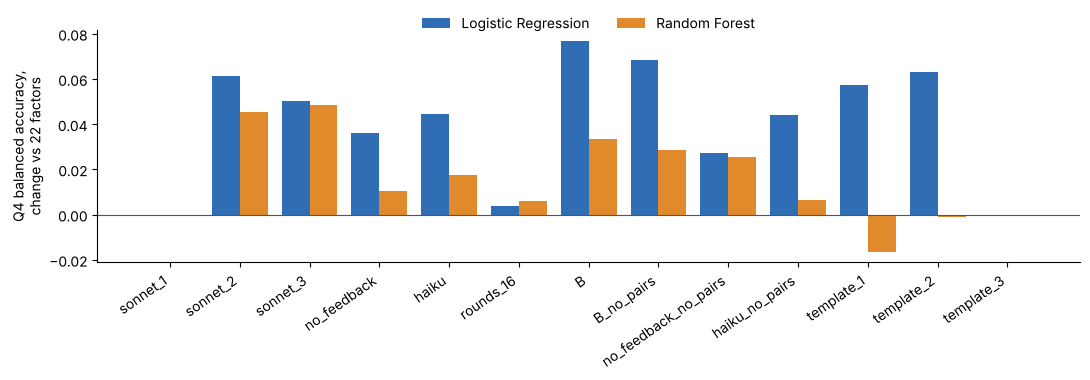

In [8]:
show = [r for r in runs if r != 'one_at_a_time']
x = np.arange(len(show))

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(x - 0.2, q4.loc[show, 'LR bal. acc.'], width=0.4, label='Logistic Regression', color='#2f6db5')
ax.bar(x + 0.2, q4.loc[show, 'RF bal. acc.'], width=0.4, label='Random Forest', color='#e08a2b')
ax.axhline(0, color='#555', linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(show, rotation=35, ha='right')
ax.set_ylabel('Q4 balanced accuracy,\nchange vs 22 factors')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, 1.12))
plt.tight_layout()
plt.show()

## 6. Comparing with Taiyu and Leyao

We all start from the same 22 factors, the same data and the same quarterly split. The one quarter we all report is **Q4 2025**, so this table uses that quarter only. A quick check that we really share the setting: my 22-factor Logistic Regression scores AUC 0.478 on Q4 2025, the same 0.478 Leyao showed for the original 22 factors.

Leyao's number is from her 22 October slides. Taiyu's loop measures MAE and RMSE, so I've asked him for the up/down measures (AUC and balanced accuracy) on the same quarter.

In [9]:
by_year = pd.read_csv('results/stage2/ablation/by_year.csv')
by_year['run'] = by_year['run'].replace({v: k for k, v in old_names.items()})
q4_2025 = by_year[by_year['year'] == 2025]

def auc(run, features, model):
    rows = q4_2025[(q4_2025['run'] == run) & (q4_2025['features'] == features) & (q4_2025['model'] == model)]
    return rows['auc'].iloc[0] if len(rows) else np.nan

table = [{'approach': '22 Stage 1 factors',
          'LR AUC': auc('B', 'stage1_22', 'logistic_regression'),
          'RF AUC': auc('B', 'stage1_22', 'random_forest')}]
for run in ['B', 'sonnet_2', 'sonnet_3', 'no_feedback', 'haiku', 'rounds_16']:
    table.append({'approach': f'Abu: {run}',
                  'LR AUC': auc(run, 'stage1_plus_llm', 'logistic_regression'),
                  'RF AUC': auc(run, 'stage1_plus_llm', 'random_forest')})
table.append({'approach': 'Leyao: 22 + 16 selected', 'LR AUC': 0.540, 'RF AUC': np.nan})
table.append({'approach': 'Taiyu: (to add)', 'LR AUC': np.nan, 'RF AUC': np.nan})
pd.DataFrame(table).set_index('approach').round(3)

,LR AUC,RF AUC
approach,,
22 Stage 1 factors,0.478,0.495
Abu: B,0.436,0.417
Abu: sonnet_2,0.505,0.471
Abu: sonnet_3,0.410,0.476
Abu: no_feedback,0.504,0.494
Abu: haiku,0.393,0.405
Abu: rounds_16,0.409,0.468
Leyao: 22 + 16 selected,0.540,NaN
Taiyu: (to add),NaN,NaN


On this one quarter, Leyao's Logistic Regression (0.540) is clearly ahead of all of mine (best 0.505). Q4 2025 is a hard quarter for my factors: run B, which looked good when averaged over four years, scores 0.436 here. A single quarter of 63 days is a small test, but it's the fairest like-for-like comparison we have right now. The next step is to put all three of our approaches through the same four Q4 quarters.

## Summary

**What I did.** I took my Stage 2 loop apart and changed one part at a time: feedback off, a smaller model, more rounds, pair trials off, one-at-a-time judging, and template formulas instead of Claude. I also repeated the normal setting three times. That came to 14 runs in the table (11 new this week and 3 from October), all on the same data, the same split, the same rules and the same Python setup, and all tested once on Q4.

**What I found.**

1. **More rounds didn't help.** In the 16-round run the factors looked best on the Q3 checks but did worst on Q4, and the formulas became much harder to explain. It looks like overfitting to the checks.
2. **Claude did better than template formulas for Random Forest.** On Logistic Regression the two are similar. On Random Forest Claude's factors helped (+0.031 on average) and the templates didn't (-0.006).
3. **Testing factors together did better than testing them alone**, on the same 48 factors. This supports the 20 October change.
4. **The report cards and the pair trials seem to help a little.** Both point the right way, but the effects are small.
5. **Haiku came close to Sonnet** at a lower cost.
6. **The selection is fragile.** The same setting picked 0, 3 or 4 factors, and a change of scikit-learn version changed the team. All of the points above are about the same size as this run-to-run noise, so they are directions to check further, not proven results.

**Limits.** Each Q4 is only 63 trading days. Most settings ran only once, and the Sonnet runs only three times. On Q4 2025 alone, Leyao's approach is ahead of mine.

**Next steps.**
- Put Taiyu's, Leyao's and my approaches through the same four Q4 quarters.
- Repeat the most interesting settings (no feedback, Haiku) a few more times.
- Look at stopping earlier rather than running longer, since more rounds led to overfitting.